# 01 · Graph Basics: State, Nodes, Edges  🟢 Beginner

LangGraph models an application as a **graph**:

| Concept | What it is | In code |
|---|---|---|
| **State** | Shared data that flows through the graph | a `TypedDict` (or Pydantic / dataclass) |
| **Node** | A step = a plain Python function `state -> partial update` | `builder.add_node("name", fn)` |
| **Edge** | Which node runs next | `builder.add_edge("a", "b")` |
| **START / END** | Virtual entry and exit points | `from langgraph.graph import START, END` |
| **Compile** | Validates & turns the builder into a runnable app | `graph = builder.compile()` |

No LLM in this notebook: first understand the machinery.

## 1. Your first graph

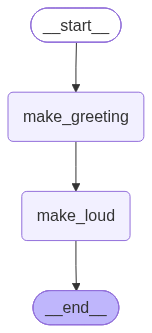

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from helpers import show_graph

class GreetState(TypedDict):
    name: str
    greeting: str

def make_greeting(state: GreetState) -> dict:
    print("➡️  make_greeting got:", state)
    return {"greeting": f"Hello, {state['name']}!"}        # return ONLY the keys you change

def make_loud(state: GreetState) -> dict:
    print("➡️  make_loud got:", state)
    return {"greeting": state["greeting"].upper() + " 🎉"}

builder = StateGraph(GreetState)
builder.add_node("make_greeting", make_greeting)
builder.add_node("make_loud", make_loud)
builder.add_edge(START, "make_greeting")
builder.add_edge("make_greeting", "make_loud")
builder.add_edge("make_loud", END)

graph = builder.compile()
show_graph(graph)

In [2]:
result = graph.invoke({"name": "Asha"})
print("\nFinal state:", result)

➡️  make_greeting got: {'name': 'Asha'}
➡️  make_loud got: {'name': 'Asha', 'greeting': 'Hello, Asha!'}

Final state: {'name': 'Asha', 'greeting': 'HELLO, ASHA! 🎉'}


**Key idea:** a node returns a *partial update*. LangGraph merges it into the state.
By default a key is **overwritten** by the new value.

## 2. Watching each step with `stream`

`invoke` gives you the final state. `stream(..., stream_mode="updates")` yields what each node returned.

In [3]:
for step in graph.stream({"name": "Asha"}, stream_mode="updates"):
    print(step)

➡️  make_greeting got: {'name': 'Asha'}
{'make_greeting': {'greeting': 'Hello, Asha!'}}
➡️  make_loud got: {'name': 'Asha', 'greeting': 'Hello, Asha!'}
{'make_loud': {'greeting': 'HELLO, ASHA! 🎉'}}


## 3. Reducers: how updates are merged

Sometimes you want to **accumulate** instead of overwrite (e.g. a log, a list of messages).
Annotate the key with a *reducer* function: `Annotated[type, reducer]`. `operator.add` concatenates lists.

In [4]:
import operator
from typing import Annotated

class PipelineState(TypedDict):
    text: str                                   # overwritten on every update
    log: Annotated[list[str], operator.add]     # appended on every update

def clean(state: PipelineState):
    return {"text": state["text"].strip().lower(), "log": ["cleaned"]}

def count_words(state: PipelineState):
    n = len(state["text"].split())
    return {"log": [f"counted {n} words"]}

def reverse(state: PipelineState):
    return {"text": state["text"][::-1], "log": ["reversed"]}

b = StateGraph(PipelineState)
b.add_node(clean); b.add_node(count_words); b.add_node(reverse)   # name defaults to function name
b.add_edge(START, "clean"); b.add_edge("clean", "count_words")
b.add_edge("count_words", "reverse"); b.add_edge("reverse", END)
pipeline = b.compile()

pipeline.invoke({"text": "   LangGraph Makes Agents Reliable  ", "log": ["start"]})

{'text': 'elbailer stnega sekam hparggnal',
 'log': ['start', 'cleaned', 'counted 4 words', 'reversed']}

## 4. Custom reducer

A reducer is just `fn(current_value, update) -> new_value`. Here: keep a *set-like* list of unique tags.

In [5]:
def merge_unique(current: list[str], new: list[str]) -> list[str]:
    return current + [t for t in new if t not in current]

class TagState(TypedDict):
    tags: Annotated[list[str], merge_unique]

b = StateGraph(TagState)
b.add_node("a", lambda s: {"tags": ["python", "ai"]})
b.add_node("b", lambda s: {"tags": ["ai", "langgraph"]})
b.add_edge(START, "a"); b.add_edge("a", "b"); b.add_edge("b", END)
b.compile().invoke({"tags": ["python"]})

{'tags': ['python', 'ai', 'langgraph']}

## 5. Input / output schemas (cleaner APIs)

Internal state can have helper keys you don't want callers to see.

In [6]:
class InputState(TypedDict):
    question: str

class OutputState(TypedDict):
    answer: str

class OverallState(InputState, OutputState):
    scratch: str          # internal only

def think(state: OverallState):
    return {"scratch": f"(thinking about '{state['question']}')"}

def answer(state: OverallState):
    return {"answer": f"Answer based on {state['scratch']}"}

b = StateGraph(OverallState, input_schema=InputState, output_schema=OutputState)
b.add_node(think); b.add_node(answer)
b.add_edge(START, "think"); b.add_edge("think", "answer"); b.add_edge("answer", END)
b.compile().invoke({"question": "What is a node?"})   # 'scratch' is hidden from the output

{'answer': "Answer based on (thinking about 'What is a node?')"}

## ✅ Recap & exercises
* **State** = shared dict; **nodes** return partial updates; **edges** define order.
* Default merge = overwrite; use `Annotated[..., reducer]` to accumulate.
* `invoke` → final state, `stream(stream_mode="updates")` → per-node updates.

**Try it:** add a node `add_emoji` between `make_greeting` and `make_loud`; give `PipelineState` a `word_count: int` key set by `count_words`.